# output.ipynb — Mục 4.2.2: Suy luận Bayesian CPT và ANFIS rule học được
## Thực nghiệm 1 — A2_soft_exp1

Notebook này đọc trực tiếp artifact JSON của thực nghiệm 1 (**không chạy lại training**) và sinh các biểu đồ phục vụ mục 4.2 của khóa luận:
- Cấu trúc Bayesian Network
- CPT heatmap (log-likelihood ratio)
- Raw CPT grouped bars
- Sample BN inference trace
- ANFIS rule importance heatmap

---
## Phần 1 — Load experiment artifacts

In [2]:
"""
Phần 1: Load experiment artifacts từ folder A2_soft_exp1.
Không chạy lại training. Chỉ đọc JSON artifact đã có sẵn.
"""
import json
import re
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path

# ---------------------------------------------------------------
# Đường dẫn artifact — dùng pathlib để tương thích Kaggle/Linux
# ---------------------------------------------------------------
# Notebook này nằm ở gốc project; artifact nằm trong:
#   artifacts/A2_soft_exp1/
# Nếu chạy trên Kaggle, sửa ROOT cho phù hợp.
ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

EXP_NAME = "A2_soft_exp1"

# Updated path: no double nesting (fixed May 20, 2026)
EXP_DIR = ROOT / "artifacts" / EXP_NAME

REQUIRED_FILES = {
    "bn_details": EXP_DIR / "bn_details.json",
    "anfis_rules": EXP_DIR / "anfis_rules.json",
}

# Kiểm tra file tồn tại — báo lỗi rõ ràng thay vì silent fail
missing = [name for name, path in REQUIRED_FILES.items() if not path.exists()]
if missing:
    raise FileNotFoundError(
        f"[ERROR] Các file artifact sau không tìm thấy trong {EXP_DIR}:\n"
        + "\n".join(f"  - {name}: {REQUIRED_FILES[name]}" for name in missing)
    )

# Load JSON
with open(REQUIRED_FILES["bn_details"], encoding="utf-8") as f:
    bn_details = json.load(f)

with open(REQUIRED_FILES["anfis_rules"], encoding="utf-8") as f:
    anfis_rules = json.load(f)

# ---------------------------------------------------------------
# In summary
# ---------------------------------------------------------------
cfg = bn_details["configuration"]
metrics = bn_details["test_metrics"]
bn_struct = bn_details["bn_structure"]

print("=" * 60)
print(f"Experiment  : {bn_details['experiment']}")
print(f"Threshold   : {bn_details['threshold']}")
print(f"Test metrics: acc={metrics['acc']:.4f}  bal_acc={metrics['bal_acc']:.4f}"
      f"  macro_f1={metrics['macro_f1']:.4f}  AUC={metrics['auc']:.4f}")
print(f"BN root     : {bn_struct['root']}  states={bn_struct['root_states']}")
print(f"Evidence    : {bn_struct['evidence_nodes']}")
print(f"n_bins      : {bn_struct['n_bins']}  bin_names={bn_struct['bin_names']}")
print("=" * 60)

# Tạo thư mục output
FIG_DIR = EXP_DIR / "figures_4_2"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print(f"Output dir  : {FIG_DIR}")

Experiment  : A2_soft_exp1
Threshold   : 0.55
Test metrics: acc=0.7513  bal_acc=0.7519  macro_f1=0.7511  AUC=0.7734
BN root     : CL  states=['rest', 'task']
Evidence    : ['Temp', 'HR', 'GSR', 'RR']
n_bins      : 5  bin_names=['very_low', 'low', 'med', 'high', 'very_high']
Output dir  : D:\SGU(1)\official\4-2\v2-neee\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2


Saved figure to: D:\SGU(1)\official\4-2\v2-neee\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2\fig_unclear_boundary_hr_mean.png


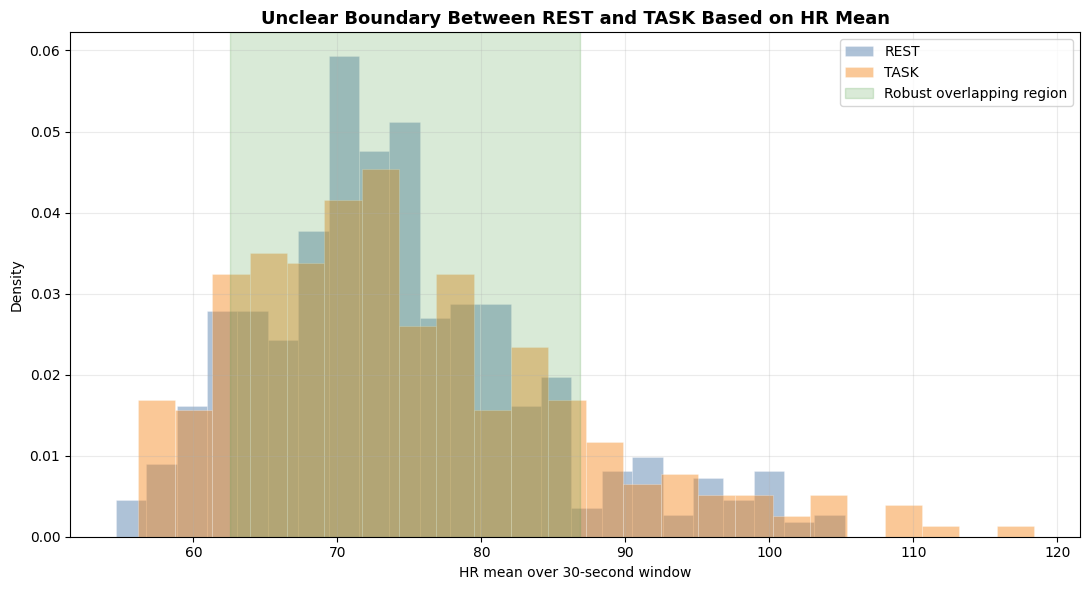

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# Figure: Unclear REST-TASK Boundary Based on HR Mean
# ============================================================

NOTEBOOK_ROOT = ROOT if "ROOT" in globals() else Path.cwd().resolve()
if NOTEBOOK_ROOT.name == "notebooks":
    NOTEBOOK_ROOT = NOTEBOOK_ROOT.parent
if not (NOTEBOOK_ROOT / "last_30s_segments").exists() and (NOTEBOOK_ROOT / "fts-anfis-bns-final").exists():
    NOTEBOOK_ROOT = NOTEBOOK_ROOT / "fts-anfis-bns-final"

DATA_DIR = NOTEBOOK_ROOT / "last_30s_segments"

# Load data explicitly from the segment files so the notebook does not depend on
# variables created in earlier cells or external globals.
hr_path = DATA_DIR / "hr.xlsx"
labels_path = DATA_DIR / "labels.xlsx"

if not hr_path.exists():
    raise FileNotFoundError(f"Missing HR data file: {hr_path}")
if not labels_path.exists():
    raise FileNotFoundError(f"Missing label data file: {labels_path}")

hr_data = pd.read_excel(hr_path, index_col=0)
labels_data = pd.read_excel(labels_path, index_col=0)

# HR mean over each 30-second window.
hr_mean = hr_data.mean(axis=1)

# Match the project pipeline convention:
#   rest -> REST; all non-rest workload levels -> TASK.
def map_label_to_rest_task(x):
    if pd.isna(x):
        return np.nan
    if isinstance(x, str):
        return "REST" if x.strip().lower() == "rest" else "TASK"
    try:
        return "REST" if int(x) <= 0 else "TASK"
    except (TypeError, ValueError):
        return "TASK"

if "level" not in labels_data.columns:
    raise KeyError("labels.xlsx/label_df must contain a 'level' column.")

labels = labels_data["level"].apply(map_label_to_rest_task)

plot_df = pd.DataFrame(
    {
        "hr_mean": hr_mean,
        "label": labels,
    }
).dropna()

rest_vals = plot_df.loc[plot_df["label"] == "REST", "hr_mean"].to_numpy()
task_vals = plot_df.loc[plot_df["label"] == "TASK", "hr_mean"].to_numpy()

if len(rest_vals) == 0 or len(task_vals) == 0:
    raise ValueError("Both REST and TASK samples are required to plot the overlap figure.")

# Robust overlap region: intersection between the central 10-90 percentile ranges.
rest_q10, rest_q90 = np.percentile(rest_vals, [10, 90])
task_q10, task_q90 = np.percentile(task_vals, [10, 90])

overlap_left = max(rest_q10, task_q10)
overlap_right = min(rest_q90, task_q90)

fig, ax = plt.subplots(figsize=(11, 6))

ax.hist(
    rest_vals,
    bins=24,
    density=True,
    alpha=0.45,
    label="REST",
    color="#4C78A8",
    edgecolor="white",
    linewidth=0.4,
)

ax.hist(
    task_vals,
    bins=24,
    density=True,
    alpha=0.45,
    label="TASK",
    color="#F58518",
    edgecolor="white",
    linewidth=0.4,
)

if overlap_left < overlap_right:
    ax.axvspan(
        overlap_left,
        overlap_right,
        alpha=0.22,
        label="Robust overlapping region",
        color="#54A24B",
    )

ax.set_title("Unclear Boundary Between REST and TASK Based on HR Mean", fontsize=13, weight="bold")
ax.set_xlabel("HR mean over 30-second window")
ax.set_ylabel("Density")
ax.legend(frameon=True)
ax.grid(alpha=0.25)
fig.tight_layout()

# Save high-resolution figure for thesis/slide usage.
output_dir = FIG_DIR if "FIG_DIR" in globals() else NOTEBOOK_ROOT
output_path = output_dir / "fig_unclear_boundary_hr_mean.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")
print(f"Saved figure to: {output_path}")
plt.show()




This figure illustrates that the distributions of REST and TASK are not clearly separable using HR mean alone. A substantial overlapping region exists, meaning that the same HR mean value may correspond to REST for one subject but TASK for another subject. Therefore, a fixed threshold-based decision boundary is likely to be unstable and may cause misclassification. This motivates the use of fuzzy representation, where each physiological value can partially belong to multiple states instead of being assigned to a single hard class.


---
## Phần 2 — Figure: Cấu trúc Bayesian Network

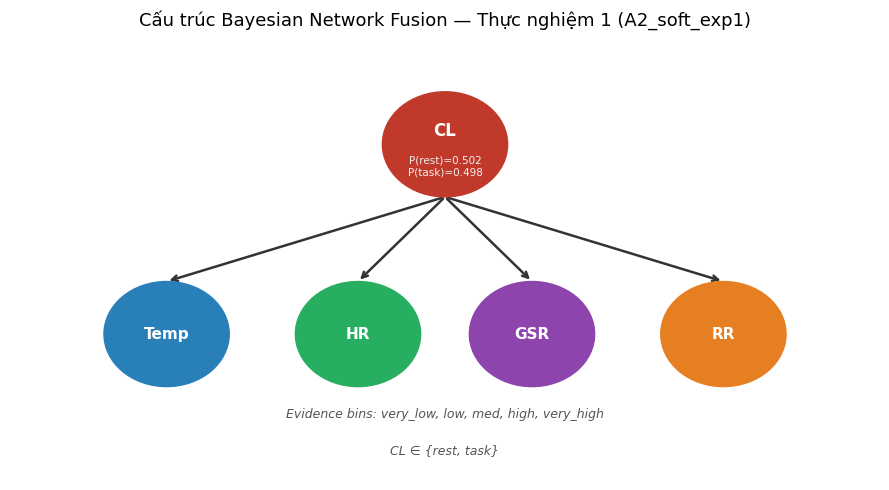

[saved] D:\SGU(1)\official\4-2\v2-neee\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2\fig_bn_structure.png


In [4]:
"""
Phần 2: Vẽ sơ đồ cấu trúc Bayesian Network.
Dùng matplotlib patches — không cần pyAgrum, chạy được trên Kaggle.
"""

prior = bn_details["prior"]
evidence_nodes = bn_struct["evidence_nodes"]   # ['Temp', 'HR', 'GSR', 'RR']
bin_names = bn_struct["bin_names"]

fig, ax = plt.subplots(figsize=(9, 5))
ax.set_xlim(0, 10)
ax.set_ylim(0, 6)
ax.axis("off")

# Hàm helper vẽ node tròn với text
def draw_node(ax, cx, cy, label, sub="", color="#4C72B0", fontsize=11):
    circle = plt.Circle((cx, cy), 0.72, color=color, zorder=3)
    ax.add_patch(circle)
    ax.text(cx, cy + (0.18 if sub else 0), label,
            ha="center", va="center", fontsize=fontsize,
            fontweight="bold", color="white", zorder=4)
    if sub:
        ax.text(cx, cy - 0.3, sub, ha="center", va="center",
                fontsize=7.5, color="#f0f0f0", zorder=4)

# Hàm helper vẽ mũi tên
def draw_arrow(ax, x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", lw=1.8, color="#333333"),
                zorder=2)

# ----- Root node CL -----
cl_x, cl_y = 5.0, 4.6
draw_node(ax, cl_x, cl_y, "CL",
          f"P(rest)={prior['rest']:.3f}\nP(task)={prior['task']:.3f}",
          color="#c0392b", fontsize=12)

# ----- Evidence nodes -----
ev_positions = {
    "Temp": (1.8, 2.0),
    "HR":   (4.0, 2.0),
    "GSR":  (6.0, 2.0),
    "RR":   (8.2, 2.0),
}
ev_colors = {"Temp": "#2980b9", "HR": "#27ae60", "GSR": "#8e44ad", "RR": "#e67e22"}

for sig, (ex, ey) in ev_positions.items():
    draw_node(ax, ex, ey, sig, color=ev_colors[sig], fontsize=11)
    # Vẽ mũi tên từ CL xuống evidence
    draw_arrow(ax, cl_x, cl_y - 0.72, ex, ey + 0.72)

# ----- Chú thích bins -----
bins_str = ", ".join(bin_names)
ax.text(5.0, 0.9, f"Evidence bins: {bins_str}",
        ha="center", va="center", fontsize=9, color="#555555",
        style="italic")
ax.text(5.0, 0.4, "CL ∈ {rest, task}",
        ha="center", va="center", fontsize=9, color="#555555",
        style="italic")

ax.set_title("Cấu trúc Bayesian Network Fusion — Thực nghiệm 1 (A2_soft_exp1)",
             fontsize=13, pad=12)

fig.tight_layout()
out_path = FIG_DIR / "fig_bn_structure.png"
fig.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[saved] {out_path}")

---
## Phần 3 — Figure: CPT Log-Likelihood Ratio Heatmap

[saved] D:\SGU(1)\official\4-2\v2-neee\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2\cpt_log_likelihood_ratio.csv
Bin     very_low     low     med    high  very_high
Signal                                             
Temp     -0.0567 -0.1346 -0.0251  0.1004     0.1156
HR       -0.6226 -0.2150  0.1004  0.0376     0.7055
GSR      -0.4875 -0.0567  0.0692  0.1639     0.3053
RR       -1.3363 -0.4422  0.1639  0.4876     1.0427


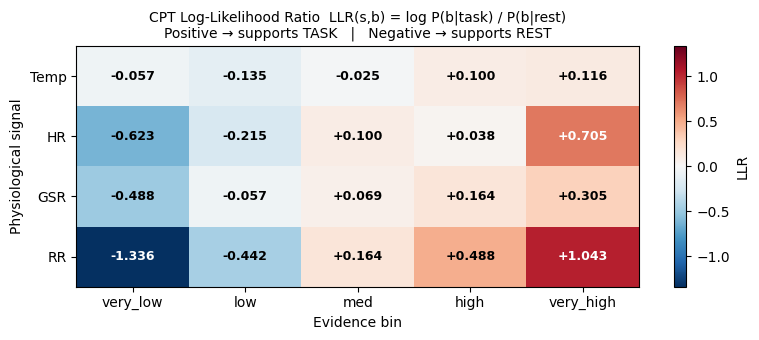

[saved] D:\SGU(1)\official\4-2\v2-neee\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2\fig_cpt_llr_heatmap.png


In [11]:
"""
Phần 3: CPT Log-Likelihood Ratio heatmap.
LLR(s, b) = log( P(E_s=b | task) / P(E_s=b | rest) )
- Giá trị dương: bin b ủng hộ lớp TASK
- Giá trị âm: bin b ủng hộ lớp REST
"""
cpt = bn_details["cpt_tables"]   # dict: signal -> {rest: {bin: p}, task: {bin: p}}
signals = evidence_nodes          # ['Temp', 'HR', 'GSR', 'RR']

# Tính LLR cho mỗi (signal, bin)
llr_data = {}
for sig in signals:
    llr_data[sig] = {}
    for b in bin_names:
        p_task = cpt[sig]["task"][b]
        p_rest = cpt[sig]["rest"][b]
        # Clip tránh log(0)
        llr_data[sig][b] = np.log(np.maximum(p_task, 1e-9) / np.maximum(p_rest, 1e-9))

# Tạo DataFrame — hàng: signal, cột: bin
df_llr = pd.DataFrame(llr_data, index=bin_names).T  # (n_signals, n_bins)
df_llr.index.name = "Signal"
df_llr.columns.name = "Bin"

# Lưu CSV
csv_path = FIG_DIR / "cpt_log_likelihood_ratio.csv"
df_llr.to_csv(csv_path)
print(f"[saved] {csv_path}")
print(df_llr.round(4))

# ---- Vẽ heatmap bằng matplotlib imshow ----
fig, ax = plt.subplots(figsize=(8, 3.5))
mat = df_llr.values.astype(float)    # (4, 5)
vmax = np.abs(mat).max()

im = ax.imshow(mat, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")

# Trục
ax.set_xticks(range(len(bin_names)))
ax.set_xticklabels(bin_names, fontsize=10)
ax.set_yticks(range(len(signals)))
ax.set_yticklabels(signals, fontsize=10)
ax.set_xlabel("Evidence bin", fontsize=10)
ax.set_ylabel("Physiological signal", fontsize=10)
ax.set_title("CPT Log-Likelihood Ratio  LLR(s,b) = log P(b|task) / P(b|rest)\n"
             "Positive → supports TASK   |   Negative → supports REST", fontsize=10)

# Annotate giá trị
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        val = mat[i, j]
        color = "white" if abs(val) > 0.5 * vmax else "black"
        ax.text(j, i, f"{val:+.3f}", ha="center", va="center",
                fontsize=9, color=color, fontweight="bold")

plt.colorbar(im, ax=ax, label="LLR")
fig.tight_layout()
out_path = FIG_DIR / "fig_cpt_llr_heatmap.png"
fig.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[saved] {out_path}")

---
## Phần 4 — Figure: Raw CPT Grouped Bars (mỗi tín hiệu một figure)

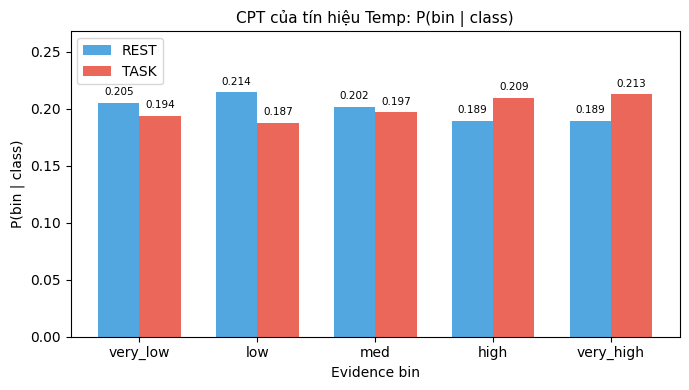

[saved] D:\SGU(1)\official\4-2\v2-neee\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2\fig_cpt_Temp.png


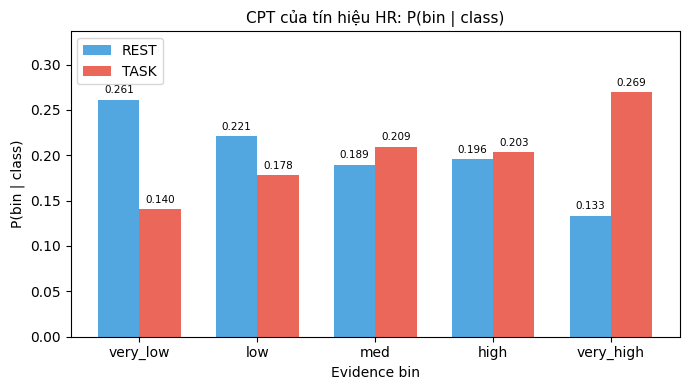

[saved] D:\SGU(1)\official\4-2\v2-neee\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2\fig_cpt_HR.png


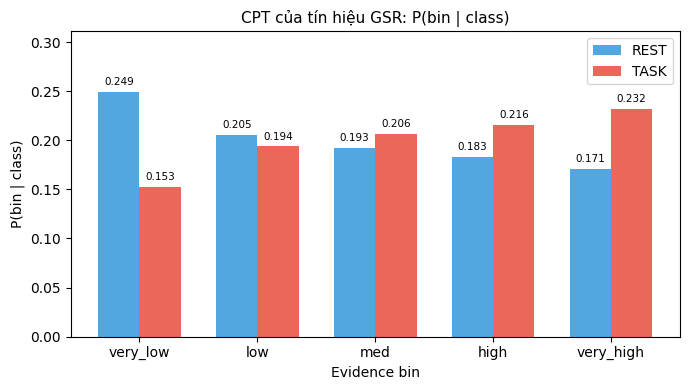

[saved] D:\SGU(1)\official\4-2\v2-neee\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2\fig_cpt_GSR.png


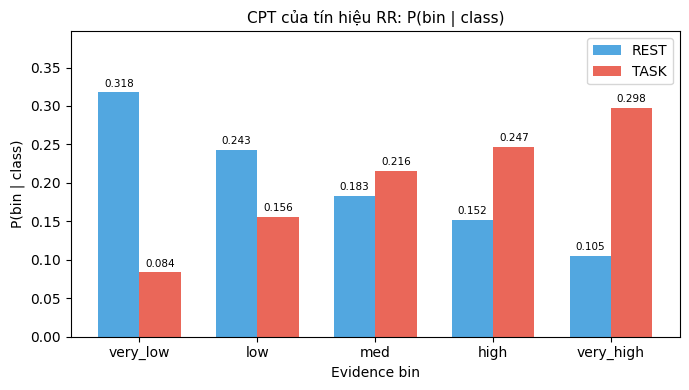

[saved] D:\SGU(1)\official\4-2\v2-neee\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2\fig_cpt_RR.png


In [6]:
"""
Phần 4: Grouped bar chart P(bin | class) cho mỗi tín hiệu.
Mỗi hình là một tín hiệu với hai nhóm bar: rest và task.
"""
bar_width = 0.35
x = np.arange(len(bin_names))

for sig in signals:
    p_rest = np.array([cpt[sig]["rest"][b] for b in bin_names])
    p_task = np.array([cpt[sig]["task"][b] for b in bin_names])

    fig, ax = plt.subplots(figsize=(7, 4))

    bars_rest = ax.bar(x - bar_width / 2, p_rest, bar_width,
                       label="REST", color="#3498db", alpha=0.85)
    bars_task = ax.bar(x + bar_width / 2, p_task, bar_width,
                       label="TASK", color="#e74c3c", alpha=0.85)

    # Annotate giá trị xác suất lên bar
    for bar in bars_rest:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.005,
                f"{h:.3f}", ha="center", va="bottom", fontsize=7.5)
    for bar in bars_task:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.005,
                f"{h:.3f}", ha="center", va="bottom", fontsize=7.5)

    ax.set_xticks(x)
    ax.set_xticklabels(bin_names, fontsize=10)
    ax.set_ylim(0, max(p_rest.max(), p_task.max()) * 1.25)
    ax.set_xlabel("Evidence bin", fontsize=10)
    ax.set_ylabel("P(bin | class)", fontsize=10)
    ax.set_title(f"CPT của tín hiệu {sig}: P(bin | class)", fontsize=11)
    ax.legend(fontsize=10)

    fig.tight_layout()
    out_path = FIG_DIR / f"fig_cpt_{sig}.png"
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"[saved] {out_path}")

---
## Phần 5 — Figure: Sample BN Inference Trace

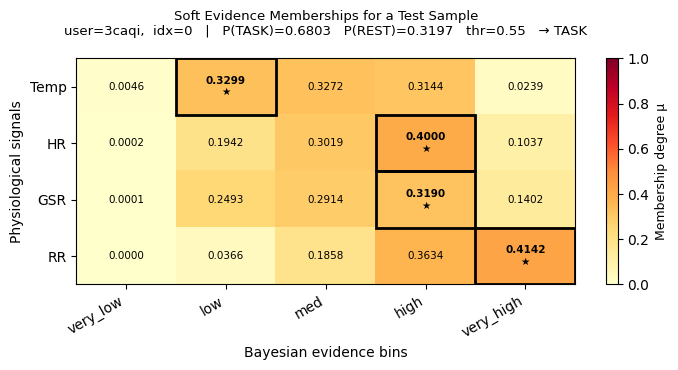

[saved] D:\SGU(1)\official\4-2\v2-neee\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2\fig_sample_soft_memberships.png
[saved] D:\SGU(1)\official\4-2\v2-neee\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2\sample_soft_memberships.csv


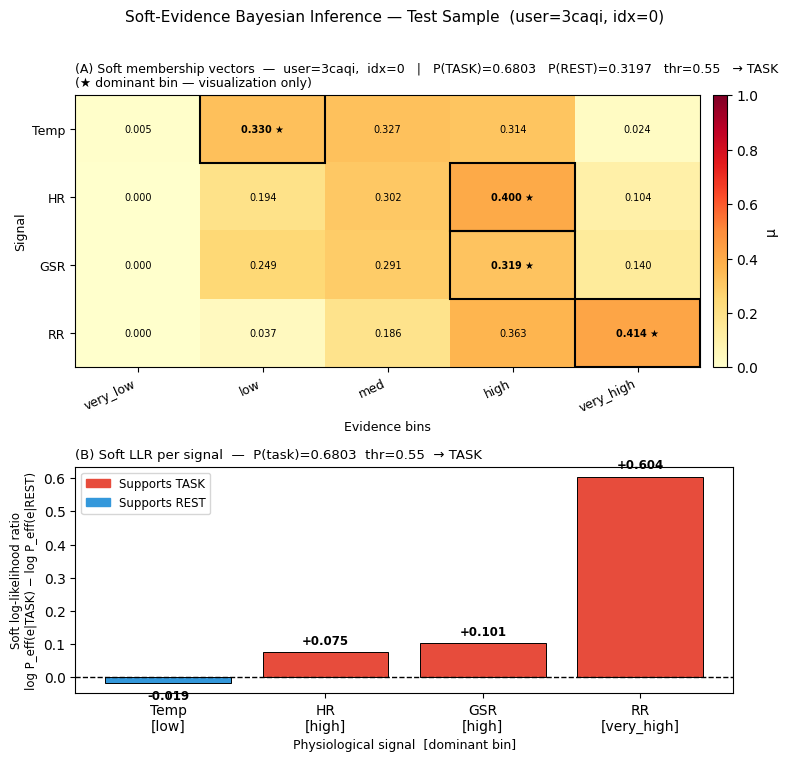

[saved] D:\SGU(1)\official\4-2\v2-neee\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2\fig_sample_soft_evidence_trace_combined.png


In [7]:
"""
Figure 4.6 — Soft Evidence Membership Heatmap.

Visualizes the Gaussian-kernel membership vector μ_{s,b}(p_s) for each
physiological signal over all Bayesian evidence bins.  This is the actual
input to soft-evidence Bayesian inference — NOT hard-bin assignment.

The dominant bin (★) is for visualization only; inference uses the full
membership vector via:

    P_eff(e_s | C=c) = Σ_b  μ_{s,b}(p_s) · P(E_s=b | C=c)
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Rectangle
from pathlib import Path
import json as _json

# Reload guard (cell can run standalone after %run main.py)
try:
    bn_details
except NameError:
    _ROOT = Path.cwd().resolve()
    if _ROOT.name == "notebooks":
        _ROOT = _ROOT.parent
    with open(_ROOT / "artifacts" / "A2_soft_exp1" / "bn_details.json", encoding="utf-8") as _f:
        bn_details = _json.load(_f)
    print("[reload] bn_details loaded from artifact JSON")

try:
    signals
except NameError:
    signals = bn_details["bn_structure"]["evidence_nodes"]

try:
    FIG_DIR
except NameError:
    _ROOT = Path.cwd().resolve()
    if _ROOT.name == "notebooks":
        _ROOT = _ROOT.parent
    FIG_DIR = _ROOT / "artifacts" / "A2_soft_exp1" / "figures_4_2"
    FIG_DIR.mkdir(parents=True, exist_ok=True)


def plot_sample_soft_memberships(
    bn_details: dict,
    signals: list,
    fig_dir,
    filename: str = "fig_sample_soft_memberships.png",
):
    """
    Plot a heatmap of soft-evidence membership vectors for a test sample.

    Parameters
    ----------
    bn_details : dict   Loaded bn_details.json artifact.
    signals    : list   Ordered list of signal names, e.g. ['Temp', 'HR', 'GSR', 'RR'].
    fig_dir    : Path   Output directory for figure and CSV.
    filename   : str    Output PNG filename.
    """
    trace = bn_details["sample_inference_trace"]

    # --- strict mode guard ---
    if trace.get("mode") != "soft":
        raise RuntimeError(
            f"Expected soft trace, got mode={trace.get('mode')!r}. "
            "Regenerate bn_details.json after fixing BNFusion.explain_sample()."
        )

    sm = trace.get("soft_memberships")
    if not sm:
        raise RuntimeError(
            "soft_memberships not found in sample_inference_trace. "
            "Please rerun main.py with A2_soft and regenerate bn_details.json."
        )

    # Bin order: prefer artifact, fallback to canonical order
    bin_names = (
        bn_details["bn_structure"].get("bin_names")
        or ["very_low", "low", "med", "high", "very_high"]
    )

    sample_idx  = trace.get("sample_index", 0)
    user_id     = trace.get("user_id", "unknown")
    post_task   = trace.get("final_posterior_task")
    threshold   = bn_details.get("threshold")
    post_rest   = (1.0 - post_task) if post_task is not None else None
    predicted   = ("TASK" if post_task >= threshold else "REST") if (post_task is not None and threshold is not None) else "?"

    # Build membership matrix (n_signals × n_bins)
    M = np.array([[sm[s][b] for b in bin_names] for s in signals])

    # ---------------------------------------------------------------
    # Figure — heatmap
    # ---------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(7.2, 3.8))
    im = ax.imshow(M, aspect="auto", vmin=0.0, vmax=1.0, cmap="YlOrRd")

    ax.set_xticks(np.arange(len(bin_names)))
    ax.set_xticklabels(bin_names, rotation=30, ha="right", fontsize=10)
    ax.set_yticks(np.arange(len(signals)))
    ax.set_yticklabels(signals, fontsize=10)

    # Annotate values; highlight dominant bin per signal
    for i in range(len(signals)):
        j_max = int(np.argmax(M[i]))
        for j in range(len(bin_names)):
            val = M[i, j]
            is_max = (j == j_max)
            text_color = "white" if val > 0.55 else "black"
            label = f"{val:.4f}\n★" if is_max else f"{val:.4f}"
            ax.text(
                j, i, label,
                ha="center", va="center",
                fontsize=7.5,
                fontweight="bold" if is_max else "normal",
                color=text_color,
            )
        # Black border around dominant cell
        ax.add_patch(Rectangle(
            (j_max - 0.5, i - 0.5), 1, 1,
            fill=False, edgecolor="black", linewidth=2.0, zorder=3,
        ))

    # Build title lines
    line1 = "Soft Evidence Memberships for a Test Sample"
    line2 = f"user={user_id},  idx={sample_idx}"
    if post_task is not None:
        line2 += f"   |   P(TASK)={post_task:.4f}   P(REST)={post_rest:.4f}   thr={threshold:.2f}   → {predicted}"
    line3 = ""

    ax.set_title(f"{line1}\n{line2}\n{line3}", fontsize=9.5)
    ax.set_xlabel("Bayesian evidence bins", fontsize=10)
    ax.set_ylabel("Physiological signals", fontsize=10)

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Membership degree μ", fontsize=9)

    fig.tight_layout()
    out_path = fig_dir / filename
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"[saved] {out_path}")

    # ---------------------------------------------------------------
    # Save CSV
    # ---------------------------------------------------------------
    df_sm = pd.DataFrame(M, columns=bin_names)
    df_sm.insert(0, "Signal", signals)
    df_sm["Dominant_bin"]         = [bin_names[int(np.argmax(row))] for row in M]
    df_sm["Dominant_membership"]  = [float(np.max(row)) for row in M]

    csv_path = fig_dir / "sample_soft_memberships.csv"
    df_sm.to_csv(csv_path, index=False)
    print(f"[saved] {csv_path}")

    return fig, M, bin_names


# Run standalone figure
fig_sm, M, bin_names_sm = plot_sample_soft_memberships(
    bn_details, signals, FIG_DIR
)

# ---------------------------------------------------------------
# Optional: Combined 2-panel figure (heatmap + LLR bar chart)
# ---------------------------------------------------------------
trace    = bn_details["sample_inference_trace"]
bn_struct = bn_details["bn_structure"]
sw        = bn_details.get("signal_weights", {s: 1.0 for s in signals})
cpt       = bn_details["cpt_tables"]
prior     = bn_details["prior"]

contributions = {sig: trace["log_likelihood_ratio"][sig] for sig in signals}
dom_bins      = trace.get("dominant_bins", trace.get("evidence_bins", {}))
sm_data       = trace["soft_memberships"]

sample_idx = trace.get("sample_index", 0)
user_id    = trace.get("user_id", "unknown")
threshold  = bn_details["threshold"]
post_task  = trace["final_posterior_task"]
post_rest  = 1.0 - post_task
predicted  = "TASK" if post_task >= threshold else "REST"

fig2, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(8, 7.5),
    gridspec_kw={"height_ratios": [1.2, 1]},
)

# --- Panel A: membership heatmap ---
im2 = ax_top.imshow(M, aspect="auto", vmin=0.0, vmax=1.0, cmap="YlOrRd")
ax_top.set_xticks(np.arange(len(bin_names_sm)))
ax_top.set_xticklabels(bin_names_sm, rotation=25, ha="right", fontsize=9)
ax_top.set_yticks(np.arange(len(signals)))
ax_top.set_yticklabels(signals, fontsize=9)

for i in range(len(signals)):
    j_max = int(np.argmax(M[i]))
    for j in range(len(bin_names_sm)):
        val = M[i, j]
        is_max = (j == j_max)
        tc = "white" if val > 0.55 else "black"
        ax_top.text(j, i, f"{val:.3f}" + (" ★" if is_max else ""),
                    ha="center", va="center", fontsize=7,
                    fontweight="bold" if is_max else "normal", color=tc)
    ax_top.add_patch(Rectangle(
        (j_max - 0.5, i - 0.5), 1, 1,
        fill=False, edgecolor="black", linewidth=1.5, zorder=3,
    ))

fig2.colorbar(im2, ax=ax_top, label="μ", fraction=0.03, pad=0.02)
ax_top.set_title(
    f"(A) Soft membership vectors  —  user={user_id},  idx={sample_idx}"
    f"   |   P(TASK)={post_task:.4f}   P(REST)={post_rest:.4f}   thr={threshold:.2f}   → {predicted}\n"
    f"(★ dominant bin — visualization only)",
    fontsize=9.0, loc="left",
)
ax_top.set_xlabel("Evidence bins", fontsize=9)
ax_top.set_ylabel("Signal", fontsize=9)

# --- Panel B: LLR bar chart ---
vals   = [contributions[s] for s in signals]
lbls   = [f"{s}\n[{dom_bins.get(s,'')}]" for s in signals]
colors = ["#e74c3c" if v > 0 else "#3498db" for v in vals]

bars = ax_bot.bar(lbls, vals, color=colors, edgecolor="black", linewidth=0.7)
ax_bot.axhline(0, color="black", linewidth=1.0, linestyle="--")

for bar, val in zip(bars, vals):
    y_pos = val + 0.015 if val >= 0 else val - 0.06
    ax_bot.text(bar.get_x() + bar.get_width() / 2, y_pos,
                f"{val:+.3f}", ha="center", va="bottom",
                fontsize=8.5, fontweight="bold")

ax_bot.set_ylabel(
    "Soft log-likelihood ratio\nlog P_eff(e|TASK) − log P_eff(e|REST)",
    fontsize=8.5,
)
ax_bot.set_xlabel("Physiological signal  [dominant bin]", fontsize=9)
ax_bot.set_title(
    f"(B) Soft LLR per signal  —  P(task)={post_task:.4f}  "
    f"thr={threshold:.2f}  → {predicted}",
    fontsize=9.5, loc="left",
)
patch_t = mpatches.Patch(color="#e74c3c", label="Supports TASK")
patch_r = mpatches.Patch(color="#3498db", label="Supports REST")
ax_bot.legend(handles=[patch_t, patch_r], fontsize=8.5)

fig2.suptitle(
    f"Soft-Evidence Bayesian Inference — Test Sample  (user={user_id}, idx={sample_idx})",
    fontsize=11, y=1.01,
)
fig2.tight_layout()
combined_path = FIG_DIR / "fig_sample_soft_evidence_trace_combined.png"
fig2.savefig(combined_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[saved] {combined_path}")


---
## Phan 6A - Figure: ANFIS Rule Importance Heatmap


ANFIS feature importance (sum |coef|):
FTS_feature   P(L|L)   P(M|L)  P(H|L)  P(L|M)  P(M|M)  P(H|M)   P(L|H)  \
Signal                                                                   
Temp          0.7736   1.0153  0.7946  0.8214  0.9265  0.6977   0.8696   
HR            3.8631   4.4408  3.8304  2.3550  4.4510  5.7859   1.9600   
GSR           7.0911  10.1943  3.9242  1.1609  1.0019  0.1623   8.3124   
RR           13.0842  11.6013  4.6670  6.8580  6.5720  9.1182  11.6339   

FTS_feature  P(M|H)   P(H|H)  
Signal                        
Temp         1.1063   0.8737  
HR           2.1659   2.3545  
GSR          9.7960   3.9610  
RR           4.6926  12.8968  
[saved] D:\SGU(1)\official\4-2\v2-neee\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2\anfis_rule_importance.csv


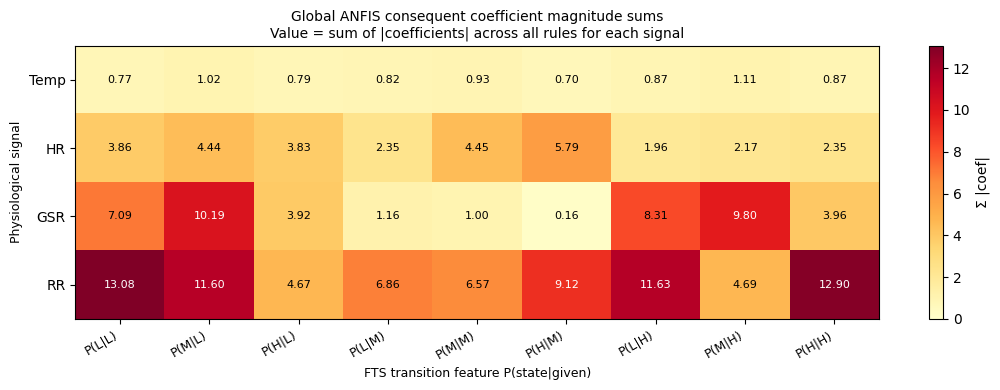

[saved] D:\SGU(1)\official\4-2\v2-neee\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2\fig_anfis_rule_importance.png


In [8]:
"""
Phần 6: ANFIS Rule Importance Heatmap.
Phân tích các luật TSK học được từ file anfis_rules.json.

Mỗi luật có dạng:
  Ri: IF <feature> is Gauss(c=..., σ=...) AND ... THEN y = coef*<feature> + ...

Tính tổng |coefficient| của mỗi feature trên tất cả rule của signal đó.
Features là các transition probability của FTS: P(L|L), P(M|L), ..., P(H|H)
"""

# Tất cả feature name có thể xuất hiện (FTS 3-set, 9 features)
FEATURE_NAMES = [
    "P(L|L)", "P(M|L)", "P(H|L)",
    "P(L|M)", "P(M|M)", "P(H|M)",
    "P(L|H)", "P(M|H)", "P(H|H)",
]

# ---------------------------------------------------------------
# Parser: trích feature và coefficient từ dòng THEN
# ---------------------------------------------------------------
_coef_re = re.compile(
    r"([+-]?\s*\d+\.\d+)\*P\(([LMH])\|([LMH])\)"
)

def parse_rule_consequent(rule_str: str) -> dict:
    """
    Trích các cặp (feature_name, coefficient) từ phần THEN của rule string.
    Ví dụ: "THEN y = 0.1172*P(M|L) + ..."
    Trả về dict: {'P(M|L)': 0.1172, ...}
    """
    # Lấy phần sau THEN
    if "THEN" not in rule_str:
        return {}
    then_part = rule_str.split("THEN")[1]
    result = {}
    for match in _coef_re.finditer(then_part):
        coef_str, state, given = match.groups()
        coef = float(coef_str.replace(" ", ""))
        feat = f"P({state}|{given})"
        # Tổng hợp nếu feature xuất hiện nhiều lần trong rule
        result[feat] = result.get(feat, 0.0) + coef
    return result

# ---------------------------------------------------------------
# Tính importance matrix (signal x feature)
# ---------------------------------------------------------------
importance = {}
for sig in signals:
    if sig not in anfis_rules:
        importance[sig] = {f: 0.0 for f in FEATURE_NAMES}
        continue
    sig_importance = {f: 0.0 for f in FEATURE_NAMES}
    for rule_str in anfis_rules[sig]:
        coefs = parse_rule_consequent(rule_str)
        for feat, coef in coefs.items():
            if feat in sig_importance:
                sig_importance[feat] += abs(coef)   # tổng |coefficient|
    importance[sig] = sig_importance

df_imp = pd.DataFrame(importance, index=FEATURE_NAMES).T   # (signals x features)
df_imp.index.name = "Signal"
df_imp.columns.name = "FTS_feature"

print("ANFIS feature importance (sum |coef|):")
print(df_imp.round(4))

# Lưu CSV
csv_imp = FIG_DIR / "anfis_rule_importance.csv"
df_imp.to_csv(csv_imp)
print(f"[saved] {csv_imp}")

# ---------------------------------------------------------------
# Vẽ heatmap importance
# ---------------------------------------------------------------
mat_imp = df_imp.values.astype(float)  # (4, 9)
vmax_imp = mat_imp.max() if mat_imp.max() > 0 else 1.0

fig, ax = plt.subplots(figsize=(11, 4))
im2 = ax.imshow(mat_imp, cmap="YlOrRd", vmin=0, vmax=vmax_imp, aspect="auto")

ax.set_xticks(range(len(FEATURE_NAMES)))
ax.set_xticklabels(FEATURE_NAMES, fontsize=9, rotation=30, ha="right")
ax.set_yticks(range(len(signals)))
ax.set_yticklabels(signals, fontsize=10)
ax.set_xlabel("FTS transition feature P(state|given)", fontsize=9)
ax.set_ylabel("Physiological signal", fontsize=9)
ax.set_title(
    "Global ANFIS consequent coefficient magnitude sums\n"
    "Value = sum of |coefficients| across all rules for each signal",
    fontsize=10
)

# Annotate
for i in range(mat_imp.shape[0]):
    for j in range(mat_imp.shape[1]):
        val = mat_imp[i, j]
        color = "white" if val > 0.65 * vmax_imp else "black"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center",
                fontsize=8, color=color)

plt.colorbar(im2, ax=ax, label="Σ |coef|")
fig.tight_layout()
out_path = FIG_DIR / "fig_anfis_rule_importance.png"
fig.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[saved] {out_path}")

  ANFIS RULE BASE  (IF-THEN rules per signal channel)

--- ANFIS RULE BASE - Temp (6 rules) ---
  R1: IF P(L|L) is Gauss(c=0.0001, σ=0.0154) AND P(M|L) is Gauss(c=0.1769, σ=0.0887) AND P(H|L) is Gauss(c=0.8230, σ=0.0888) AND P(L|M) is Gauss(c=0.0001, σ=0.0154) AND P(M|M) is Gauss(c=0.1768, σ=0.0887) AND P(H|M) is Gauss(c=0.8231, σ=0.0888) AND P(L|H) is Gauss(c=0.0001, σ=0.0154) AND P(M|H) is Gauss(c=0.1768, σ=0.0886) AND P(H|H) is Gauss(c=0.8231, σ=0.0887) THEN y = -0.0027*P(L|L) +0.1172*P(M|L) +0.0792*P(H|L) -0.0027*P(L|M) +0.0999*P(M|M) +0.0965*P(H|M) -0.0027*P(L|H) +0.0845*P(M|H) +0.1120*P(H|H) +0.1938
  R2: IF P(L|L) is Gauss(c=0.2860, σ=0.0859) AND P(M|L) is Gauss(c=0.7103, σ=0.0842) AND P(H|L) is Gauss(c=0.0037, σ=0.0297) AND P(L|M) is Gauss(c=0.2858, σ=0.0859) AND P(M|M) is Gauss(c=0.7104, σ=0.0841) AND P(H|M) is Gauss(c=0.0037, σ=0.0297) AND P(L|H) is Gauss(c=0.2857, σ=0.0858) AND P(M|H) is Gauss(c=0.7106, σ=0.0841) AND P(H|H) is Gauss(c=0.0038, σ=0.0297) THEN y = 0.0985*P(L|L)

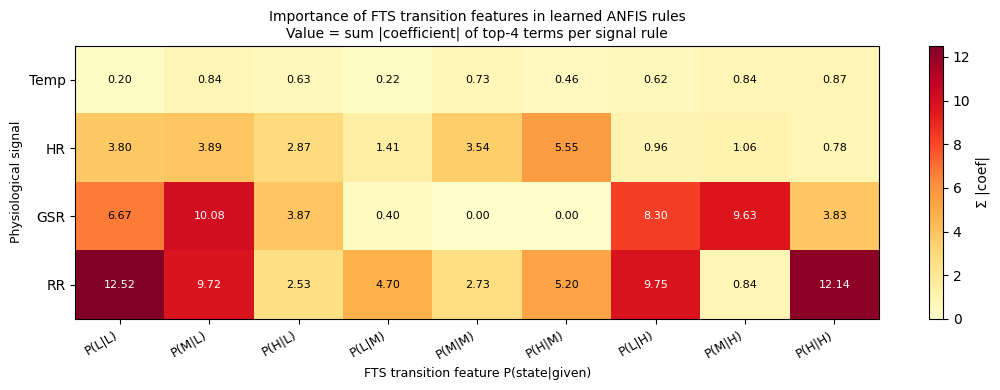

[saved] D:\SGU(1)\official\4-2\v2-neee\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2\fig_anfis_rule_importance.png


In [9]:
"""
Phan 6B: ANFIS Rule Base and Rule Importance Heatmap.

This cell reads TSK rules from anfis_rules.json, prints the rule base per
signal, then computes the importance heatmap using the same display logic:
for each rule, only the top-4 consequent coefficients by absolute value are
accumulated.
"""

# Fixed signal order for stable output.
signals = ["Temp", "HR", "GSR", "RR"]

# FTS 3-set transition feature names.
FEATURE_NAMES = [
    "P(L|L)", "P(M|L)", "P(H|L)",
    "P(L|M)", "P(M|M)", "P(H|M)",
    "P(L|H)", "P(M|H)", "P(H|H)",
]

TOP_K_PER_RULE = 4
SIGMA = chr(963)
SUM = chr(931)

# ---------------------------------------------------------------
# Parser: extract feature and coefficient from the THEN part
# ---------------------------------------------------------------
_coef_re = re.compile(
    r"([+-]?\s*\d+(?:\.\d+)?)\s*\*\s*P\(([LMH])\|([LMH])\)"
)

def parse_rule_consequent(rule_str: str) -> dict:
    """
    Extract (feature_name, coefficient) pairs from the THEN part.
    Example: "THEN y = +0.1172*P(M|L) -0.05*P(H|M) + ..."
    Returns: {'P(M|L)': 0.1172, ...}
    """
    if "THEN" not in rule_str:
        return {}
    then_part = rule_str.split("THEN", 1)[1]
    result = {}
    for match in _coef_re.finditer(then_part):
        coef_str, state, given = match.groups()
        coef = float(coef_str.replace(" ", ""))
        feat = f"P({state}|{given})"
        result[feat] = result.get(feat, 0.0) + coef
    return result


def selected_top_terms(rule_str: str, top_k: int = TOP_K_PER_RULE) -> list[tuple[str, float]]:
    """Return top-k consequent terms actually used for the importance heatmap."""
    coefs = parse_rule_consequent(rule_str)
    return sorted(
        ((feat, coef) for feat, coef in coefs.items() if feat in FEATURE_NAMES),
        key=lambda item: abs(item[1]),
        reverse=True,
    )[:top_k]


def pretty_rule(rule_str: str) -> str:
    """Format artifact rule text close to the thesis console output."""
    return rule_str.replace("sigma=", f"{SIGMA}=")


def pretty_terms(terms: list[tuple[str, float]]) -> str:
    return ", ".join(f"{coef:+.4f}*{feat}" for feat, coef in terms)

# ---------------------------------------------------------------
# Print full ANFIS rule base and the terms selected for heatmap
# ---------------------------------------------------------------
print("=" * 68)
print("  ANFIS RULE BASE  (IF-THEN rules per signal channel)")
print("=" * 68)

selected_rows = []
for sig in signals:
    rules = anfis_rules.get(sig, [])
    print(f"\n--- ANFIS RULE BASE - {sig} ({len(rules)} rules) ---")
    for rule_idx, rule_str in enumerate(rules, start=1):
        print(f"  {pretty_rule(rule_str)}")
        terms = selected_top_terms(rule_str)
        selected_rows.append({
            "signal": sig,
            "rule": f"R{rule_idx}",
            "selected_top_terms": pretty_terms(terms),
        })

print("\n" + "=" * 68)
print(f"  TOP-{TOP_K_PER_RULE} CONSEQUENT TERMS USED FOR THE IMPORTANCE HEATMAP")
print("=" * 68)
selected_df = pd.DataFrame(selected_rows)
print(selected_df.to_string(index=False))

selected_csv = FIG_DIR / "anfis_rule_selected_terms.csv"
selected_df.to_csv(selected_csv, index=False)
print(f"[saved] {selected_csv}")

# ---------------------------------------------------------------
# Compute importance matrix (signal x feature)
# ---------------------------------------------------------------
importance = {}
for sig in signals:
    sig_importance = {f: 0.0 for f in FEATURE_NAMES}
    for rule_str in anfis_rules.get(sig, []):
        for feat, coef in selected_top_terms(rule_str):
            sig_importance[feat] += abs(coef)
    importance[sig] = sig_importance

df_imp = pd.DataFrame.from_dict(importance, orient="index", columns=FEATURE_NAMES)
df_imp.index.name = "Signal"
df_imp.columns.name = "FTS_feature"

print("\nANFIS feature importance (sum |coef| from top-4 consequent terms per rule):")
print(df_imp.round(2))
print("Importance is computed from top-4 absolute consequent coefficients per rule.")

# Save CSV
csv_imp = FIG_DIR / "anfis_rule_importance.csv"
df_imp.to_csv(csv_imp)
print(f"[saved] {csv_imp}")

# ---------------------------------------------------------------
# Plot importance heatmap
# ---------------------------------------------------------------
mat_imp = df_imp.values.astype(float)  # (4, 9)
vmax_imp = mat_imp.max() if mat_imp.max() > 0 else 1.0

fig, ax = plt.subplots(figsize=(11, 4))
im2 = ax.imshow(mat_imp, cmap="YlOrRd", vmin=0, vmax=vmax_imp, aspect="auto")

ax.set_xticks(range(len(FEATURE_NAMES)))
ax.set_xticklabels(FEATURE_NAMES, fontsize=9, rotation=30, ha="right")
ax.set_yticks(range(len(signals)))
ax.set_yticklabels(signals, fontsize=10)
ax.set_xlabel("FTS transition feature P(state|given)", fontsize=9)
ax.set_ylabel("Physiological signal", fontsize=9)
ax.set_title(
    "Importance of FTS transition features in learned ANFIS rules\n"
    f"Value = sum |coefficient| of top-{TOP_K_PER_RULE} terms per signal rule",
    fontsize=10,
)

# Annotate
for i in range(mat_imp.shape[0]):
    for j in range(mat_imp.shape[1]):
        val = mat_imp[i, j]
        color = "white" if val > 0.65 * vmax_imp else "black"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center",
                fontsize=8, color=color)

plt.colorbar(im2, ax=ax, label=f"{SUM} |coef|")
fig.tight_layout()
out_path = FIG_DIR / "fig_anfis_rule_importance.png"
fig.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[saved] {out_path}")


---
## Phần 7 — Figure captions (đề xuất cho khóa luận)

| Hình | Caption tiếng Việt |
|------|-------------------|
| Hình 4.x | **Cấu trúc Bayesian Network Fusion trong thực nghiệm 1.** Nút gốc CL đại diện cho nhãn tải nhận thức (cognitive load) với hai trạng thái: *rest* và *task*. Bốn nút evidence (Temp, HR, GSR, RR) là các tín hiệu sinh lý được rời rạc hóa thành 5 bin theo phân vị. Xác suất tiên nghiệm P(rest) ≈ P(task) ≈ 0.5 cho thấy dữ liệu gần cân bằng lớp. |
| Hình 4.x | **Mức độ ủng hộ lớp task/rest của từng evidence bin thông qua log-likelihood ratio từ CPT.** Giá trị LLR(s,b) = log P(b\|task) − log P(b\|rest) dương (đỏ) biểu thị bin b ủng hộ trạng thái *task*; âm (xanh) biểu thị ủng hộ *rest*. RR và HR cho thấy xu hướng rõ rệt nhất: bin *very_high* ủng hộ mạnh *task* trong khi *very_low* ủng hộ *rest*. |
| Hình 4.x | **Phân phối CPT thô P(bin\|class) cho từng tín hiệu.** Mỗi biểu đồ grouped bar cho thấy xác suất của từng bin với hai lớp REST và TASK. Sự chênh lệch giữa hai cột trong cùng bin phản ánh độ phân biệt của tín hiệu đó. |
| Hình 4.5 | **Truy vết suy luận Bayesian theo soft evidence trên một mẫu kiểm thử.** Mỗi tín hiệu được biểu diễn bằng vector membership trên năm bin xác suất ANFIS; bin trội nhất chỉ được dùng để trực quan hóa. Các cột biểu diễn soft log-likelihood ratio giữa lớp TASK và REST, $\text{LLR}(s) = w_s \log P_\text{eff}(e_s\mid\text{TASK}) - w_s \log P_\text{eff}(e_s\mid\text{REST})$, trong đó $P_\text{eff}(e_s\mid C) = \sum_b \mu_{s,b}(p_s)\,P(E_s{=}b\mid C)$. Thanh đỏ (dương) ủng hộ *task*; thanh xanh (âm) ủng hộ *rest*. Posterior cuối cùng P(task) vượt ngưỡng threshold, cho kết quả dự đoán đúng lớp. |
| Hình 4.x | **Mức độ quan trọng của các đặc trưng chuyển trạng thái FTS trong các luật ANFIS học được.** Giá trị trong mỗi ô là tổng trị tuyệt đối của hệ số TSK tương ứng trên toàn bộ luật của tín hiệu đó. Các đặc trưng có giá trị cao (màu đậm) đóng vai trò chính trong việc phân biệt tải nhận thức thông qua ANFIS. |

---
## Tổng kết — Danh sách file đã lưu


In [10]:
"""
Phần cuối: In danh sách tất cả file đã lưu trong figures_4_2/
"""
print("=" * 60)
print("Danh sách file đã tạo trong", FIG_DIR)
print("=" * 60)
saved_files = sorted(FIG_DIR.glob("*"))
for f in saved_files:
    size_kb = f.stat().st_size / 1024
    print(f"  {f.name:<45}  {size_kb:>7.1f} KB")

Danh sách file đã tạo trong D:\SGU(1)\official\4-2\v2-neee\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2
  anfis_rule_importance.csv                          0.5 KB
  anfis_rule_selected_terms.csv                      1.7 KB
  cpt_log_likelihood_ratio.csv                       0.5 KB
  fig_anfis_rule_importance.png                    175.9 KB
  fig_bn_structure.png                             149.4 KB
  fig_cpt_GSR.png                                   85.4 KB
  fig_cpt_HR.png                                    86.8 KB
  fig_cpt_llr_heatmap.png                          131.6 KB
  fig_cpt_RR.png                                    89.6 KB
  fig_cpt_Temp.png                                  81.2 KB
  fig_sample_bayesian_prediction.png               135.1 KB
  fig_sample_soft_evidence_trace_combined.png      274.8 KB
  fig_sample_soft_memberships.png                  176.4 KB
  fig_unclear_boundary_hr_mean.png                 118.3 KB
  sample_bn_infe